# 01 - Data exploration: Home Credit Default Risk

Goal: understand the data before building a PD model.

Issue 2

## Imports and load

In [69]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

DATA_DIR = "../data/raw"
df = pd.read_csv(f"{DATA_DIR}/application_train.csv")
print(f"Rows: {df.shape[0]:,}  Columns: {df.shape[1]}")

Rows: 307,511  Columns: 122


## First look at the data

The first five records, transposed so that each of the 122 columns appears as a row.

In [70]:
pd.set_option("display.max_rows", None)
display(df.head().T)

,0,1,2,3,4
SK_ID_CURR,100002,100003,100004,100006,100007
TARGET,1,0,0,0,0
NAME_CONTRACT_TYPE,Cash loans,Cash loans,Revolving loans,Cash loans,Cash loans
CODE_GENDER,M,F,M,F,M
FLAG_OWN_CAR,N,N,Y,N,N
FLAG_OWN_REALTY,Y,N,Y,Y,Y
CNT_CHILDREN,0,0,0,0,0
AMT_INCOME_TOTAL,202500.0,270000.0,67500.0,135000.0,121500.0
AMT_CREDIT,406597.5,1293502.5,135000.0,312682.5,513000.0
AMT_ANNUITY,24700.5,35698.5,6750.0,29686.5,21865.5


## Target

`TARGET = 1` means the client had payment difficulties (our "default"), `0` otherwise.

In [71]:
default_rate = df["TARGET"].mean() #average of the TARGET column, which indicates the default rate
print(f"Default rate: {default_rate:.2%}") #in percentage with 2 decimal places
df["TARGET"].value_counts()

Default rate: 8.07%


TARGET
0    282686
1     24825
Name: count, dtype: int64

## Column types

In [72]:
print(df.dtypes.value_counts())
print("\nNon-numeric columns and their number of categories:")
df.select_dtypes(exclude="number").nunique().sort_values(ascending=False)

float64    65
int64      41
object     16
Name: count, dtype: int64

Non-numeric columns and their number of categories:


ORGANIZATION_TYPE             58
OCCUPATION_TYPE               18
NAME_INCOME_TYPE               8
NAME_TYPE_SUITE                7
WEEKDAY_APPR_PROCESS_START     7
WALLSMATERIAL_MODE             7
NAME_FAMILY_STATUS             6
NAME_HOUSING_TYPE              6
NAME_EDUCATION_TYPE            5
FONDKAPREMONT_MODE             4
CODE_GENDER                    3
HOUSETYPE_MODE                 3
NAME_CONTRACT_TYPE             2
FLAG_OWN_CAR                   2
FLAG_OWN_REALTY                2
EMERGENCYSTATE_MODE            2
dtype: int64

## Missing values

In [73]:
missing = df.isna().mean().sort_values(ascending=False)
high_missing = missing[missing > 0.5]

pd.set_option("display.max_rows", None)   # show every row, not a shortened list
print(high_missing.map("{:.1%}".format))
print(f"Total columns with >50% missing: {len(high_missing)} of {df.shape[1]}")

COMMONAREA_MEDI             69.9%
COMMONAREA_AVG              69.9%
COMMONAREA_MODE             69.9%
NONLIVINGAPARTMENTS_MODE    69.4%
NONLIVINGAPARTMENTS_AVG     69.4%
NONLIVINGAPARTMENTS_MEDI    69.4%
FONDKAPREMONT_MODE          68.4%
LIVINGAPARTMENTS_MODE       68.4%
LIVINGAPARTMENTS_AVG        68.4%
LIVINGAPARTMENTS_MEDI       68.4%
FLOORSMIN_AVG               67.8%
FLOORSMIN_MODE              67.8%
FLOORSMIN_MEDI              67.8%
YEARS_BUILD_MEDI            66.5%
YEARS_BUILD_MODE            66.5%
YEARS_BUILD_AVG             66.5%
OWN_CAR_AGE                 66.0%
LANDAREA_MEDI               59.4%
LANDAREA_MODE               59.4%
LANDAREA_AVG                59.4%
BASEMENTAREA_MEDI           58.5%
BASEMENTAREA_AVG            58.5%
BASEMENTAREA_MODE           58.5%
EXT_SOURCE_1                56.4%
NONLIVINGAREA_MODE          55.2%
NONLIVINGAREA_AVG           55.2%
NONLIVINGAREA_MEDI          55.2%
ELEVATORS_MEDI              53.3%
ELEVATORS_AVG               53.3%
ELEVATORS_MODE

## Is missingness informative?

Some columns are mostly empty. Before dropping them, check whether being missing is itself linked to default.

In [74]:
for col in ["COMMONAREA_AVG", "OWN_CAR_AGE", "YEARS_BUILD_AVG"]:
    rate = df.groupby(df[col].isna())["TARGET"].mean()
    print(f"{col}: missing {rate[True]:.2%}, present {rate[False]:.2%}")

print(pd.crosstab(df["FLAG_OWN_CAR"], df["OWN_CAR_AGE"].isna()))

COMMONAREA_AVG: missing 8.57%, present 6.91%
OWN_CAR_AGE: missing 8.50%, present 7.24%
YEARS_BUILD_AVG: missing 8.68%, present 6.87%
OWN_CAR_AGE    False   True 
FLAG_OWN_CAR                
N                  0  202924
Y             104582       5


## Default rate by category

Default rate and number of clients for selected categorical variables.

In [75]:
for col in ["NAME_INCOME_TYPE", "NAME_EDUCATION_TYPE", "NAME_CONTRACT_TYPE"]:
    summary = df.groupby(col)["TARGET"].agg(["mean", "count"])
    summary["mean"] = summary["mean"].map("{:.1%}".format)
    print(summary.sort_values("count", ascending=False), "\n")

                       mean   count
NAME_INCOME_TYPE                   
Working                9.6%  158774
Commercial associate   7.5%   71617
Pensioner              5.4%   55362
State servant          5.8%   21703
Unemployed            36.4%      22
Student                0.0%      18
Businessman            0.0%      10
Maternity leave       40.0%       5 

                                mean   count
NAME_EDUCATION_TYPE                         
Secondary / secondary special   8.9%  218391
Higher education                5.4%   74863
Incomplete higher               8.5%   10277
Lower secondary                10.9%    3816
Academic degree                 1.8%     164 

                    mean   count
NAME_CONTRACT_TYPE              
Cash loans          8.3%  278232
Revolving loans     5.5%   29279 



## Cash loans vs revolving loans

Revolving loans have a lower default rate. Compare loan size, income and external score to find out why.

In [76]:
cols = ["AMT_CREDIT", "AMT_INCOME_TOTAL", "EXT_SOURCE_2"]
print(df.groupby("NAME_CONTRACT_TYPE")[cols].median())

df["CREDIT_INCOME_RATIO"] = df["AMT_CREDIT"] / df["AMT_INCOME_TOTAL"]
print(df.groupby("NAME_CONTRACT_TYPE")["CREDIT_INCOME_RATIO"].median())

                    AMT_CREDIT  AMT_INCOME_TOTAL  EXT_SOURCE_2
NAME_CONTRACT_TYPE                                            
Cash loans            540000.0          153000.0      0.565381
Revolving loans       270000.0          135000.0      0.571315
NAME_CONTRACT_TYPE
Cash loans         3.5
Revolving loans    2.0
Name: CREDIT_INCOME_RATIO, dtype: float64


## Gender

`CODE_GENDER` will be excluded from the model: using sex as a credit criterion is treated as discriminatory under EU and Swedish anti-discrimination rules.

In [77]:
df["CODE_GENDER"].value_counts()

CODE_GENDER
F      202448
M      105059
XNA         4
Name: count, dtype: int64

## Data quirk: DAYS_EMPLOYED

The value 365243 (about 1,000 years) is a placeholder, not a real number of days.

In [78]:
print(df["DAYS_EMPLOYED"].describe())
print(df["DAYS_EMPLOYED"].value_counts().head())

count    307511.000000
mean      63815.045904
std      141275.766519
min      -17912.000000
25%       -2760.000000
50%       -1213.000000
75%        -289.000000
max      365243.000000
Name: DAYS_EMPLOYED, dtype: float64
DAYS_EMPLOYED
 365243    55374
-200         156
-224         152
-230         151
-199         151
Name: count, dtype: int64


In [79]:
anom = df["DAYS_EMPLOYED"] == 365243
print(f"Placeholder DAYS_EMPLOYED rows: {anom.sum():,} ({anom.mean():.1%})")
print(f"Default rate, placeholder rows: {df.loc[anom, 'TARGET'].mean():.2%}")
print(f"Default rate, other rows:       {df.loc[~anom, 'TARGET'].mean():.2%}")

Placeholder DAYS_EMPLOYED rows: 55,374 (18.0%)
Default rate, placeholder rows: 5.40%
Default rate, other rows:       8.66%


In [80]:
print(df.loc[anom, "NAME_INCOME_TYPE"].value_counts())

NAME_INCOME_TYPE
Pensioner     55352
Unemployed       22
Name: count, dtype: int64


## Default rate by age group

A first look at a risk driver. `DAYS_BIRTH` is negative (days before the application).

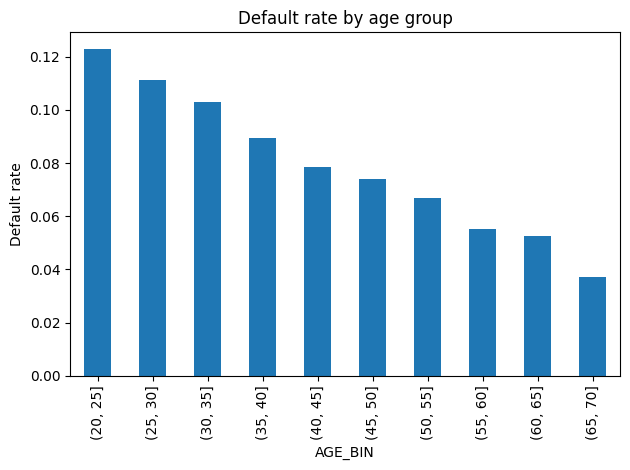

In [81]:
df["AGE_YEARS"] = -df["DAYS_BIRTH"] / 365
df["AGE_BIN"] = pd.cut(df["AGE_YEARS"], bins=range(20, 75, 5))
age_dr = df.groupby("AGE_BIN", observed=True)["TARGET"].mean()

age_dr.plot(kind="bar", title="Default rate by age group", ylabel="Default rate")
plt.tight_layout()
plt.show()

In [82]:
print(age_dr.map("{:.1%}".format))

AGE_BIN
(20, 25]    12.3%
(25, 30]    11.1%
(30, 35]    10.3%
(35, 40]     8.9%
(40, 45]     7.8%
(45, 50]     7.4%
(50, 55]     6.7%
(55, 60]     5.5%
(60, 65]     5.3%
(65, 70]     3.7%
Name: TARGET, dtype: object


## Strongest single predictors

Absolute correlation with `TARGET`, numeric columns only.

In [83]:
corr = df.select_dtypes("number").corr()["TARGET"].drop("TARGET")
corr.abs().sort_values(ascending=False).head(15)

EXT_SOURCE_3                   0.178919
EXT_SOURCE_2                   0.160472
EXT_SOURCE_1                   0.155317
AGE_YEARS                      0.078239
DAYS_BIRTH                     0.078239
REGION_RATING_CLIENT_W_CITY    0.060893
REGION_RATING_CLIENT           0.058899
DAYS_LAST_PHONE_CHANGE         0.055218
DAYS_ID_PUBLISH                0.051457
REG_CITY_NOT_WORK_CITY         0.050994
FLAG_EMP_PHONE                 0.045982
DAYS_EMPLOYED                  0.044932
REG_CITY_NOT_LIVE_CITY         0.044395
FLAG_DOCUMENT_3                0.044346
FLOORSMAX_AVG                  0.044003
Name: TARGET, dtype: float64

## Key findings

**Data and target**
- 307,511 loan applications with 122 columns.
- Default rate (TARGET = 1) is 8.07%: 24,825 defaults versus 282,686 non-defaults, about 1 to 11. Accuracy is therefore not a useful metric; Gini/AUC will be used instead.
- TARGET is Home Credit's own definition of early payment difficulties, not the regulatory default definition (CRR Article 178).

**Missing values**
- 41 of 122 columns have more than 50% missing values, mostly building variables that appear three times each (_AVG, _MODE, _MEDI).
- EXT_SOURCE_1 is 56% missing but is expected to be a strong predictor, so columns are not dropped for missingness alone.
- Some missingness is structural: OWN_CAR_AGE is missing for all 202,924 clients without a car (and 5 car owners).
- Missingness is informative: clients with missing COMMONAREA_AVG default at 8.57% versus 6.91% when present. Missing values will get their own WoE bin.

**Categorical variables**
- NAME_INCOME_TYPE is highly unbalanced. Four categories have very few clients: Unemployed (22), Student (18), Businessman (10) and Maternity leave (5). Their default rates are unreliable, so they will be merged with similar categories during binning.
- NAME_EDUCATION_TYPE shows a clear pattern: more education, lower default rate (10.9% for lower secondary, 5.4% for higher education). "Academic degree" has only 164 clients (1.8% default rate) and will be merged into "Higher education".
- ORGANIZATION_TYPE has 58 categories and will need grouping into risk groups.
- Cash loans default more often than revolving loans (8.3% vs 5.5%). External scores are similar for both, but cash loans are about 3.5 times annual income versus 2 times for revolving loans, which points to debt burden as the likely explanation.

**Data quirks**
- DAYS_EMPLOYED contains a placeholder value 365243 (about 1,000 years) in 55,374 rows (18%). These are almost all pensioners (55,352) plus the 22 unemployed clients, so the placeholder means "not employed". Their default rate is 5.40% versus 8.66% for other clients. To be replaced with a missing value plus a flag during data cleaning.
- CODE_GENDER has a third value "XNA" in 4 rows. The variable is excluded from the model anyway.

**Risk drivers (first look)**

Compared with the expert long list:

*Confirmed*
- Default rate falls steadily with age, from X% for clients aged 20–25 to Y% for 65–70.
- The strongest numeric predictors are EXT_SOURCE_3, EXT_SOURCE_2 and EXT_SOURCE_1 (absolute correlation 0.16–0.18), followed by age (0.08) and regional rating (0.06).

*Unexpected*
- DAYS_LAST_PHONE_CHANGE, DAYS_ID_PUBLISH and the address-mismatch flags (REG_CITY_NOT_WORK_CITY, REG_CITY_NOT_LIVE_CITY) are predictive and may indicate instability. They are added to the long list.
- FLAG_DOCUMENT_3 is predictive but has no documented meaning, so it is treated with caution.

Correlation only captures linear relationships in numeric variables. Final selection will use WoE/IV.


## Candidate risk drivers (expert long list)

Variables expected to predict default, chosen on business logic before statistical testing. To be confirmed or rejected with WoE/IV in the next step.

| Variable | Expected effect | Reason |
|---|---|---|
| EXT_SOURCE_1/2/3 | Higher score → lower risk | External credit scores summarise past repayment behaviour |
| CREDIT_INCOME_RATIO (derived) | Higher ratio → higher risk | A loan that is large relative to income is harder to repay |
| ANNUITY_INCOME_RATIO (derived) | Higher ratio → higher risk | Share of income going to loan payments, a key affordability measure |
| CREDIT_TERM (derived) | Longer term → higher risk | More time for the client's situation to change |
| CREDIT_GOODS_RATIO (derived) | Higher ratio → higher risk | Borrowing more than the goods cost may signal financial strain |
| AMT_INCOME_TOTAL | Higher income → lower risk | More capacity to repay |
| AMT_CREDIT | Larger loan → higher risk | Larger amounts are harder to repay, though ratios to income are likely stronger |
| AMT_ANNUITY | Higher payment → higher risk | A larger regular payment is harder to keep up with |
| NAME_CONTRACT_TYPE | Higher risk for cash loans | Larger amounts relative to income |
| NAME_INCOME_TYPE | Higher risk for working and unemployed clients | Income stability differs by source; pensioners have steady income |
| DAYS_EMPLOYED | Longer employment → lower risk | Indicates job stability. Placeholder value 365243 to be handled separately |
| OCCUPATION_TYPE | Varies by occupation | Income level and job security differ between occupations |
| ORGANIZATION_TYPE | Varies by industry | Industries differ in stability; 58 categories to be grouped |
| NAME_EDUCATION_TYPE | More education → lower risk | Linked to income level and job security |
| DAYS_BIRTH (age) | Older → lower risk | Older clients tend to have more stable income and financial experience. Sensitive characteristic: use must be justified and checked for fairness |
| NAME_FAMILY_STATUS | Married/partner → lower risk | Shared household costs and possible second income |
| CNT_CHILDREN | More children → higher risk | More dependants share the household income |
| NAME_HOUSING_TYPE | Own home → lower risk | Indicates stability and assets |
| FLAG_OWN_REALTY | Owner → lower risk | Property ownership indicates assets and stability |
| FLAG_OWN_CAR | Owner → lower risk | Indicates assets |
| REGION_POPULATION_RELATIVE | Uncertain direction | Urban and rural regions differ in income and job markets. Check for fairness: geography can act as a proxy for protected characteristics |
| REGION_RATING_CLIENT | Worse rating → higher risk | Home Credit's own regional risk rating |
| AMT_REQ_CREDIT_BUREAU_YEAR | More enquiries → higher risk | Many recent credit checks may signal a search for credit in several places |
| DAYS_LAST_PHONE_CHANGE | Recent change → higher risk | May indicate instability. Added after EDA |
| DAYS_ID_PUBLISH | Recent change → higher risk | A recently reissued ID document may indicate life changes or instability. Added after EDA |
| REG_CITY_NOT_WORK_CITY | Mismatch → higher risk | Registered address differs from work city; may indicate mobility or a less settled situation. Added after EDA |
| REG_CITY_NOT_LIVE_CITY | Mismatch → higher risk | Registered address differs from where the client lives. Added after EDA |

**Excluded up front**

- SK_ID_CURR: identifier, no predictive meaning
- CODE_GENDER: anti-discrimination
- WEEKDAY_APPR_PROCESS_START: no business logic
- NAME_TYPE_SUITE: who accompanied the client has no clear link to repayment
- The 47 building variables: mostly missing, duplicated three times, hard to explain as risk drivers

**Other variables**, such as the document flags and contact flags, have no strong prior expectation. They will still be screened with WoE/IV and kept only if they show clear predictive power and a sensible risk pattern.